# CH 421 Technical Computing 2

Option 2 (gen-AI), and the bonus question.

The two datasets from Canvas are saved in the same folder as this notebook, renamed: `homework_spectrum-1.csv` is `technical_computing_2_dataset.csv`, and `homework-bonus-spectra.csv` is `technical_computing_2_bonus_dataset.csv`.

## 1. Gen-AI used and prompts

I used Claude Opus 5.5 from Anthropic (model ID `claude-opus-5-5`), through Claude Code in the Claude desktop app, on November 6, 2026. Claude wrote and ran all of the code in this notebook.

My first prompt went in with a screenshot of the Canvas instructions (the Option 2 and bonus text, which are copied into the cells below) and the two CSV files attached:

> I would like you to help me write the code for this assignment. Do not touch any of the writing prompts except for the AI disclosure. Include the prompt and other information if applicable. I am attaching a previous technical computing assingment for your reference on the general style/way to complete the assignment. If you become confused or lack context, pause and request clarification from me before continuing. You do not need to over-engineer solutions, as the assignment is fairly simple plotting and data handling. 

Before writing anything, Claude looked through my Technical Computing 1 notebook in this repo so this one would follow the same layout.

## 2. Code

### Importing packages

In [1]:
import pandas as pd              # contains things like dataframes and arrays, used for importing data
import numpy as np               # math functions like mean and standard deviations
import matplotlib.pyplot as plt  # this package is used for making plots
import scipy.stats               # holds functions for statistics, including linear regression
from scipy.signal import find_peaks, peak_widths  # find peaks in a 1D signal, and their widths

print('packages imported')

packages imported


### Import `homework_spectrum.csv` and print the data

This dataset contains two columns: wavelength in nanometers (wavelength_nm) and the signal in arbitrary units (signal).

In [2]:
file = (r'technical_computing_2_dataset.csv')   # homework_spectrum-1.csv from Canvas, renamed

data = pd.read_csv(file, header = 0)            # import data, the first row is the header

print(data)

     wavelength_nm      signal
0       300.000000  247.101732
1       300.500501  247.391185
2       301.001001  248.787756
3       301.501502  248.840925
4       302.002002  247.083455
..             ...         ...
995     797.997998   28.380641
996     798.498498   28.280883
997     798.998999   30.635327
998     799.499499   23.881415
999     800.000000   30.384716

[1000 rows x 2 columns]


### Plot the signal versus wavelength

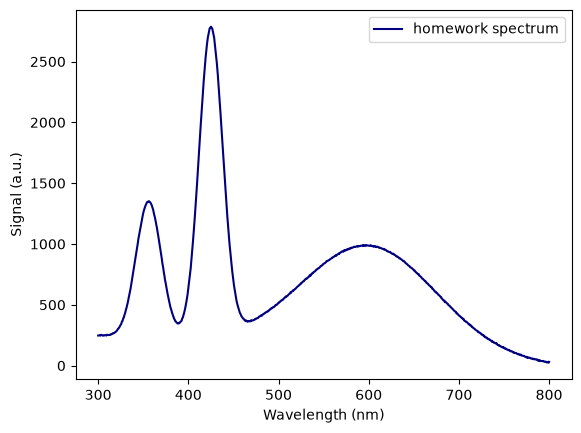

In [3]:
wavelength = np.array(data.wavelength_nm)   # nm
signal     = np.array(data.signal)          # a.u.

plt.plot(wavelength, signal, color = 'navy', label = 'homework spectrum')

plt.xlabel('Wavelength (nm)')
plt.ylabel('Signal (a.u.)')
plt.legend()
plt.show()

### Find the indices of the centers of the three major peaks

The code has to find only these three peaks.

In [ ]:
# Every small wiggle from noise is a local maximum, so asking find_peaks for
# every peak with no conditions returns far more than three
all_maxima, _ = find_peaks(signal)
print('local maxima with no conditions =', len(all_maxima))

# Prominence is how far a peak rises above the lowest point that separates it
# from a taller peak (or from the end of the data). Noise wiggles rise only a
# few a.u., while the three real bands rise hundreds to thousands of a.u., so
# requiring a prominence of at least 100 a.u. keeps only the three major peaks
peak_indices, peak_properties = find_peaks(signal, prominence = 100)

print('number of peaks found            =', len(peak_indices))
print('indices of the three major peaks =', peak_indices)
print('their prominences (a.u.)         =', np.round(peak_properties['prominences'], 1))

local maxima with no conditions = 132
number of peaks found            = 3
indices of the three major peaks = [113 250 589]
their prominences (a.u.)         = [1006.  2540.4  628.4]


### Find the wavelengths of the centers of the three major peaks

In [5]:
peak_wavelengths = wavelength[peak_indices]   # the wavelength at each peak index

print('peak center wavelengths (nm) =', np.round(peak_wavelengths, 2))

peak center wavelengths (nm) = [356.56 425.13 594.79]


### Find the maximum intensity of each of the three peaks

In [6]:
peak_intensities = signal[peak_indices]   # the signal at each peak index

print('peak maximum intensities (a.u.) =', np.round(peak_intensities, 2))
print()
for i in range(len(peak_indices)):
    print('peak', i + 1, ': index', peak_indices[i],
          ', center', round(peak_wavelengths[i], 2), 'nm',
          ', maximum intensity', round(peak_intensities[i], 2), 'a.u.')

peak maximum intensities (a.u.) = [1351.33 2786.73  991.  ]

peak 1 : index 113 , center 356.56 nm , maximum intensity 1351.33 a.u.
peak 2 : index 250 , center 425.13 nm , maximum intensity 2786.73 a.u.
peak 3 : index 589 , center 594.79 nm , maximum intensity 991.0 a.u.


### Plot the spectrum with markers at the three peaks

The markers sit at each peak's center wavelength and maximum intensity.

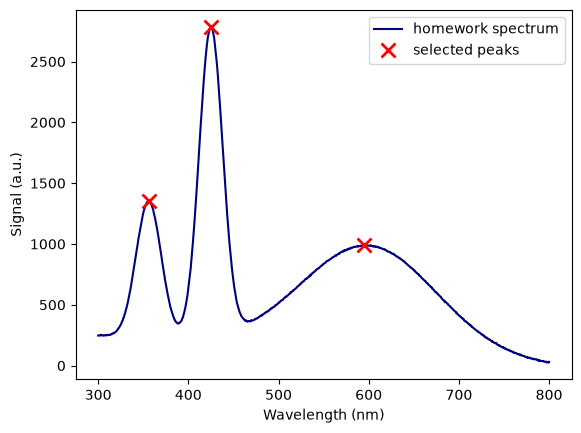

In [7]:
plt.plot(wavelength, signal, color = 'navy', label = 'homework spectrum')
plt.plot(peak_wavelengths, peak_intensities, linestyle = '', marker = 'x',
         markersize = 10, markeredgewidth = 2, color = 'red', label = 'selected peaks')

plt.xlabel('Wavelength (nm)')
plt.ylabel('Signal (a.u.)')
plt.legend()
plt.show()

### Ratio of the highest energy peak intensity (p<sub>1</sub>) to the second highest energy peak intensity (p<sub>2</sub>)

A photon's energy is E = hc/λ, so the shortest wavelength peak has the highest energy.

In [8]:
h = 6.62607015E-34      # Planck's constant (J s)
c = 2.99792458E8        # speed of light (m/s)
eV = 1.602176634E-19    # J per eV

peak_energies = h*c/(peak_wavelengths*1E-9)/eV   # nm to m, then J to eV

order = np.argsort(peak_energies)[::-1]   # peak positions from highest to lowest energy

print('peaks from highest to lowest energy:')
for i in order:
    print('  ', round(peak_wavelengths[i], 2), 'nm =', round(peak_energies[i], 3), 'eV, intensity',
          round(peak_intensities[i], 2), 'a.u.')
print()

p1 = peak_intensities[order[0]]   # highest energy peak
p2 = peak_intensities[order[1]]   # second highest energy peak
ratio = p1/p2

print('p1 =', round(p1, 2), 'a.u.  (peak at', round(peak_wavelengths[order[0]], 2), 'nm)')
print('p2 =', round(p2, 2), 'a.u.  (peak at', round(peak_wavelengths[order[1]], 2), 'nm)')
print()
print('ratio = p1/p2 =', ratio)
print('ratio = p1/p2 = %.3f' % ratio)

peaks from highest to lowest energy:
   356.56 nm = 3.477 eV, intensity 1351.33 a.u.
   425.13 nm = 2.916 eV, intensity 2786.73 a.u.
   594.79 nm = 2.084 eV, intensity 991.0 a.u.

p1 = 1351.33 a.u.  (peak at 356.56 nm)
p2 = 2786.73 a.u.  (peak at 425.13 nm)

ratio = p1/p2 = 0.4849157948548466
ratio = p1/p2 = 0.485


## 3. Differences from the method shown in class

Most of this notebook uses the same tools as the Jupyter tutorial and Technical Computing 1: `pd.read_csv` to load the data, numpy arrays and functions like `np.mean` and `np.linspace`, `plt.plot` for the figures, and `scipy.stats.linregress` for the calibration line in the bonus. The main difference is how peaks are chosen.

With the class tools, I'd look at the plot, cut the data into a range around each peak, and take `np.argmax` in each range. Claude used `find_peaks` from `scipy.signal` instead, which we didn't use in the tutorial or in Technical Computing 1. By itself it returns every point that's higher than both of its neighbors, and in this spectrum that's 132 points, almost all of them noise. The `prominence = 100` setting is what narrows it to three: a peak has to stand at least 100 a.u. above the lowest point between it and the next taller peak. Noise bumps only stand a few a.u. tall, so the three real bands are all that's left, and nobody has to choose wavelength ranges by eye. The checks in part 4 do it the class way too, and get the same three indices.

A few other functions weren't in either of those notebooks:

- `peak_widths`, also from `scipy.signal`, measures how wide a peak is at half its height. It's only used in a check.
- `np.argsort` gives the order that would sort an array, and `[::-1]` flips it, so `np.argsort(peak_energies)[::-1]` lists the peaks from highest to lowest energy. Claude converted each wavelength to an energy with E = hc/λ instead of just assuming which peak was p<sub>1</sub>.
- `np.where` returns the indices where a condition is true, and `np.array_equal` checks that two arrays are identical. Both are in the checks.
- In the bonus, `plt.subplots` stacks two plots on one wavelength axis, and `np.zeros` makes an empty array that a loop fills with the slope and R² at each wavelength.
- `'%.3f' % ratio` prints a number to three decimal places.

## 4. Why the AI-generated answer is reasonable

The second plot is a good quick check for how good/bad the answer is. Each red marker sits right on top of a peak, and none of them landed on a noise bump. Reading the graph manually, the first two peaks top out around 1350 and 2790 a.u., so p<sub>1</sub>/p<sub>2</sub> should be roughly 0.48, and the code gets 0.485.

It also matters whether the three peaks depend on the prominence setting, and they don't. Any value from 20 to 500 a.u. gives the same three indices, because the real bands rise at least 600 a.u. above their surroundings while the biggest noise bump rises about 7 a.u. Doing it the class way, with `np.argmax` over a range around each band, gives the same indices too. Both checks are in the cell below.

The energy order is right as well. With E = hc/λ, the 356.6 nm peak is at 3.48 eV and the 425.1 nm peak is at 2.92 eV, so p<sub>1</sub> is the shorter-wavelength peak, even though it's the smaller one. The flat baseline below 310 nm has about 1.7 a.u. of noise, which moves the ratio by less than 0.001.

The one problem child is the 595 nm band. It's comedically large, about 140 nm wide at half height, and nearly flat on top, so noise decides which point ends up highest, and its center could be off by a few nm. That band isn't part of the ratio, though.

In [9]:
# Check 1: the same three peaks for a wide range of prominence thresholds
for p in [20, 50, 100, 200, 500]:
    idx, _ = find_peaks(signal, prominence = p)
    print('prominence >=', p, 'a.u. ->', idx)
print()

# Check 2: a simpler method, the largest signal in a window around each band
windows = [(300, 390), (390, 460), (460, 800)]   # nm, split at the minima between the bands
argmax_indices = []
for low, high in windows:
    in_window = np.where((wavelength >= low) & (wavelength < high))[0]
    argmax_indices.append(in_window[np.argmax(signal[in_window])])
print('np.argmax in each window ->', np.array(argmax_indices))
print('same as find_peaks?       ', np.array_equal(argmax_indices, peak_indices))
print()

# Check 3: noise on the flat baseline below 310 nm, and what it does to the ratio
noise = np.std(signal[wavelength < 310], ddof = 1)
ratio_uncertainty = ratio*np.sqrt((noise/p1)**2 + (noise/p2)**2)
print('baseline noise (standard deviation below 310 nm) =', round(noise, 2), 'a.u.')
print('ratio = %.4f +/- %.4f' % (ratio, ratio_uncertainty))
print()

# Check 4: width of each band at half height
widths, _, _, _ = peak_widths(signal, peak_indices, rel_height = 0.5)
step = wavelength[1] - wavelength[0]   # nm between points
print('full width at half height (nm) =', np.round(widths*step, 1))

prominence >= 20 a.u. -> [113 250 589]
prominence >= 50 a.u. -> [113 250 589]
prominence >= 100 a.u. -> [113 250 589]
prominence >= 200 a.u. -> [113 250 589]
prominence >= 500 a.u. -> [113 250 589]

np.argmax in each window -> [113 250 589]
same as find_peaks?        True

baseline noise (standard deviation below 310 nm) = 1.67 a.u.
ratio = 0.4849 +/- 0.0007

full width at half height (nm) = [ 30.4  30.7 139.7]


## Bonus question

Use the five spectra in `homework-bonus-spectra.csv` to build a calibration curve. Use technical computing to select the wavelength at which you will build the calibration curve, and find the intensity of that peak in each spectrum. Plot the calibration curve and describe the rationale for selecting the wavelength.

### Import and plot the five spectra

     wavelength_nm  signal_1mM  signal_2mM  signal_3mM  signal_4mM  signal_5mM
0       300.000000  254.366106  250.311994  254.582710  259.485401  253.668051
1       300.500501  255.683193  247.403599  251.690754  244.995121  262.901736
2       301.001001  249.163578  254.703114  242.028691  245.056838  243.206474
3       301.501502  253.246748  242.188354  246.991837  250.012631  250.762465
4       302.002002  249.614806  259.498942  253.335506  241.344416  235.861289
..             ...         ...         ...         ...         ...         ...
995     797.997998   39.339520   40.692747   49.566109   60.892086   89.453496
996     798.498498   29.563388   31.481382   45.607927   60.970028   77.054883
997     798.998999   22.400869   29.483613   44.392436   66.129039   86.274190
998     799.499499   33.254374   24.943570   41.622336   71.364890   76.873035
999     800.000000   26.851309   28.128444   35.327733   61.705490   76.342541

[1000 rows x 6 columns]


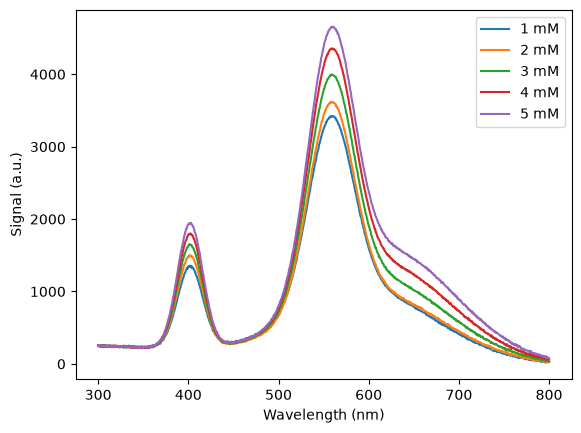

In [10]:
bonus_file = (r'technical_computing_2_bonus_dataset.csv')   # homework-bonus-spectra.csv from Canvas, renamed

bonus = pd.read_csv(bonus_file, header = 0)

print(bonus)

bonus_wavelength = np.array(bonus.wavelength_nm)
spectra = np.array(bonus.T.iloc[1:])             # one row per spectrum, 1 mM to 5 mM
concentration = np.array([1, 2, 3, 4, 5])        # mM, from the column names

for i in range(len(concentration)):
    plt.plot(bonus_wavelength, spectra[i], label = str(concentration[i]) + ' mM')

plt.xlabel('Wavelength (nm)')
plt.ylabel('Signal (a.u.)')
plt.legend()
plt.show()

### Find the candidate peaks

Every spectrum has two bands, one near 401 nm and one near 559 nm. The peak positions come from the average of the five spectra, which is less noisy than any single one.

In [11]:
for i in range(len(concentration)):
    idx, _ = find_peaks(spectra[i], prominence = 100)
    print(concentration[i], 'mM: peaks at', np.round(bonus_wavelength[idx], 1), 'nm')
print()

average_spectrum = np.mean(spectra, axis = 0)
band_indices, _ = find_peaks(average_spectrum, prominence = 100)
print('peaks in the average spectrum:', np.round(bonus_wavelength[band_indices], 1), 'nm')

1 mM: peaks at [401.6 559.3] nm
2 mM: peaks at [401.1 557.8] nm
3 mM: peaks at [401.6 559.3] nm
4 mM: peaks at [402.6 559.3] nm
5 mM: peaks at [401.6 560.8] nm

peaks in the average spectrum: [401.6 559.3] nm


### Compare the two peaks as calibration wavelengths

At each peak, fit signal against concentration and see how far the points scatter from the line, compared with the noise. The noise comes from 300 to 320 nm, where there's no band, as the scatter around a straight line.

In [12]:
# Noise: scatter about a straight line in the empty region from 300 to 320 nm
empty = bonus_wavelength < 320
noise_each = []
for i in range(len(concentration)):
    line = scipy.stats.linregress(bonus_wavelength[empty], spectra[i][empty])
    leftover = spectra[i][empty] - (line.slope*bonus_wavelength[empty] + line.intercept)
    noise_each.append(np.std(leftover, ddof = 2))
bonus_noise = np.mean(noise_each)
print('noise in each spectrum (a.u.) =', np.round(noise_each, 1), ', average', round(bonus_noise, 1))
print()

for j in band_indices:
    intensities = spectra[:, j]
    fit = scipy.stats.linregress(concentration, intensities)
    residuals = intensities - (fit.slope*concentration + fit.intercept)
    print('peak at', round(bonus_wavelength[j], 1), 'nm')
    print('   intensities (a.u.)    =', np.round(intensities, 1))
    print('   slope (a.u./mM)       =', round(fit.slope, 1))
    print('   intercept (a.u.)      =', round(fit.intercept, 1))
    print('   R-squared             =', round(fit.rvalue**2, 5))
    print('   residuals (a.u.)      =', np.round(residuals, 1))
    print('   largest residual / noise =', round(np.max(np.abs(residuals))/bonus_noise, 1))
    print()

noise in each spectrum (a.u.) = [6.9 6.4 6.3 6.4 6.6] , average 6.5

peak at 401.6 nm
   intensities (a.u.)    = [1356.7 1491.5 1652.8 1792.9 1947. ]
   slope (a.u./mM)       = 148.2
   intercept (a.u.)      = 1203.6
   R-squared             = 0.99938
   residuals (a.u.)      = [ 4.9 -8.5  4.6 -3.5  2.4]
   largest residual / noise = 1.3

peak at 559.3 nm
   intensities (a.u.)    = [3424.1 3616.7 3997.6 4358.2 4652.4]
   slope (a.u./mM)       = 319.8
   intercept (a.u.)      = 3050.4
   R-squared             = 0.99103
   residuals (a.u.)      = [ 53.9 -73.3 -12.2  28.6   3. ]
   largest residual / noise = 11.2



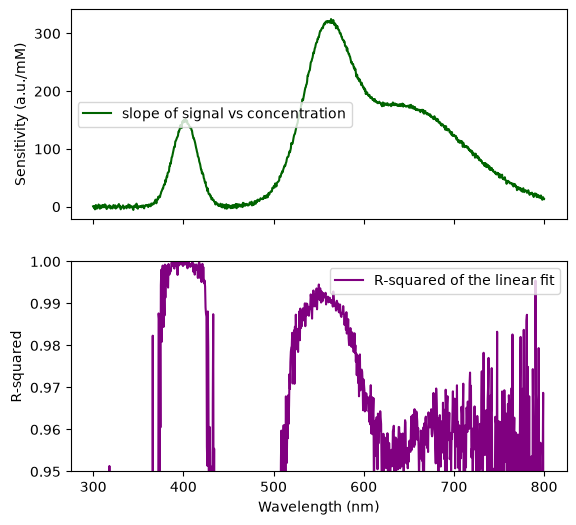

R-squared from 390 to 410 nm: lowest 0.9968 , highest 0.99997
R-squared from 540 to 580 nm: lowest 0.9849 , highest 0.99453


In [13]:
# The same comparison at every wavelength, to see whether the poor fit near
# 559 nm belongs to the whole band or to a single point
slope_at = np.zeros(len(bonus_wavelength))
r2_at = np.zeros(len(bonus_wavelength))
for j in range(len(bonus_wavelength)):
    fit = scipy.stats.linregress(concentration, spectra[:, j])
    slope_at[j] = fit.slope
    r2_at[j] = fit.rvalue**2

fig, (top, bottom) = plt.subplots(2, 1, sharex = True, figsize = (6.4, 6))
top.plot(bonus_wavelength, slope_at, color = 'darkgreen', label = 'slope of signal vs concentration')
top.set_ylabel('Sensitivity (a.u./mM)')
top.legend()
bottom.plot(bonus_wavelength, r2_at, color = 'purple', label = 'R-squared of the linear fit')
bottom.set_ylim(0.95, 1.0)
bottom.set_xlabel('Wavelength (nm)')
bottom.set_ylabel('R-squared')
bottom.legend()
plt.show()

near_400 = (bonus_wavelength > 390) & (bonus_wavelength < 410)
near_560 = (bonus_wavelength > 540) & (bonus_wavelength < 580)
print('R-squared from 390 to 410 nm: lowest', round(np.min(r2_at[near_400]), 4), ', highest', round(np.max(r2_at[near_400]), 5))
print('R-squared from 540 to 580 nm: lowest', round(np.min(r2_at[near_560]), 4), ', highest', round(np.max(r2_at[near_560]), 5))

### Calibration curve at the selected wavelength

selected wavelength = 401.6 nm
   1 mM: 1356.7 a.u.
   2 mM: 1491.5 a.u.
   3 mM: 1652.8 a.u.
   4 mM: 1792.9 a.u.
   5 mM: 1947.0 a.u.

slope       = 148.21 a.u./mM
y-intercept = 1203.6 a.u.
R-squared   = 0.99938


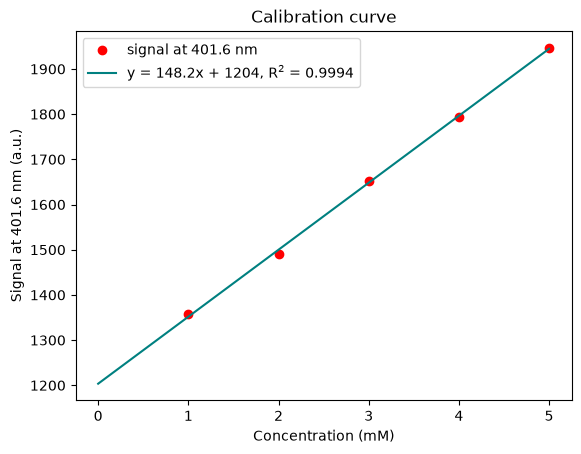

In [14]:
chosen = band_indices[0]                 # the peak near 401 nm, see the rationale below
chosen_wavelength = bonus_wavelength[chosen]
peak_intensity = spectra[:, chosen]      # intensity of that peak in each spectrum

print('selected wavelength =', round(chosen_wavelength, 2), 'nm')
for i in range(len(concentration)):
    print('  ', concentration[i], 'mM:', round(peak_intensity[i], 1), 'a.u.')
print()

slope, intercept, r_value, p_value, std_err = scipy.stats.linregress(concentration, peak_intensity)
r2 = r_value**2
print('slope       =', round(slope, 2), 'a.u./mM')
print('y-intercept =', round(intercept, 1), 'a.u.')
print('R-squared   =', round(r2, 5))

x_fit = np.linspace(0, np.max(concentration), 100)
y_fit = slope*x_fit + intercept

plt.plot(concentration, peak_intensity, linestyle = '', marker = 'o', color = 'red',
         label = 'signal at %.1f nm' % chosen_wavelength)
plt.plot(x_fit, y_fit, color = 'teal',
         label = 'y = %.1fx + %.0f, R$^2$ = %.4f' % (slope, intercept, r2))
plt.xlabel('Concentration (mM)')
plt.ylabel('Signal at %.1f nm (a.u.)' % chosen_wavelength)
plt.title('Calibration curve')
plt.legend()
plt.show()

### Rationale for the wavelength

The calibration curve uses 401.6 nm, the top of the shorter-wavelength band.

Both bands grow with concentration, so either one could carry a calibration. At first the 559 nm band looks like the better choice, since it's about twice as sensitive, around 320 a.u./mM against 148. The problem is that it doesn't stay on a straight line. At 559 nm the points miss the fit by up to 73 a.u., about 11 times the noise in the spectra, and R² is only 0.991. At 401.6 nm every point is within 9 a.u. of the line, close to the noise of about 6.5 a.u., and R² is 0.9994.

The fit is poor everywhere above about 510 nm and gets worse past 600 nm, where the sensitivity plot also has a shoulder near 650 nm. From 540 to 600 nm the residuals have the same signs at every wavelength, with the 1 mM and 4 mM samples high and the 2 mM and 3 mM samples low. Random noise wouldn't repeat like that, so something else contributes to the signal in that region and changes from sample to sample. Calibrating there would build in errors of up to about 0.2 mM (73 a.u. divided by 320 a.u./mM).

Within the 401 nm band, the peak maximum is the best spot. The slope is greatest there, and the spectrum is flattest at its top, so a small error in the instrument's wavelength changes the signal the least.